# EDA  HIỆU SUẤT TƯ VẤN & NỀN TẢNG — TECHX ACADEMY

Notebook này phân tích lần lượt từng cột cơ bản (tư vấn viên, nhà mạng, sentiment, thời gian, mức chăm sóc...) trước, rồi mới tổng hợp thành **3 KPI chính** ở cuối. Mỗi cell code có 1 cell Markdown kết luận riêng ngay bên dưới.

Nguồn dữ liệu: `Courses_of_Interest_Processed.xlsx` (đã qua bước xử lý lỗi). Những chỗ dữ liệu còn thiếu hoặc chưa đủ căn cứ kết luận chắc chắn đều được ghi rõ, không suy diễn thêm.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

FILE_PATH = "Courses_of_Interest_Processed.xlsx"
OUT_FILE = "EDA_BaoCao_full_noicon.xlsx"

def h(title):
    print("\n" + "=" * 72)
    print(title)
    print("=" * 72)

In [2]:
h("CELL 1: ĐỌC DỮ LIỆU")

df = pd.read_excel(FILE_PATH)

COL_TV = "tu_van_vien"
COL_KHOA = "quan_tam_khoa_hoc_1"
COL_NM = "nha_mang"
COL_SENT = "sentimatic"
COL_MKT = "MKT_xu_ly_data"
COL_CHOT = "thoi_gian_chuyen_sang_chot_sale"
COL_TVD = "thoi_gian_chuyen_sang_tu_van"
COL_NGAY = "so_ngay_tu_van_den_chot"
COL_DATE = "ngay_tao"


CELL 1: ĐỌC DỮ LIỆU


In [3]:
h("CELL 1: TẠO CÁC CỘT PHÂN TÍCH")

df["da_chot_sale"] = df[COL_CHOT].notna().astype(int)
df["da_tu_van"] = df[COL_TVD].notna().astype(int)
df["gio_dang_ky"] = df[COL_DATE].dt.hour
df["thu_dang_ky"] = df[COL_DATE].dt.dayofweek
df["thang_dang_ky"] = df[COL_DATE].dt.to_period("M").astype(str)
df["la_cuoi_tuan"] = df["thu_dang_ky"].isin([5, 6]).astype(int)
df["la_gio_hanh_chinh"] = df["gio_dang_ky"].between(8, 17).astype(int)


CELL 1: TẠO CÁC CỘT PHÂN TÍCH


In [4]:
h("CELL 1: KIỂM TRA DỮ LIỆU")

df_tv = df[df[COL_TV] != "Chưa xác định"].copy()

print(f"Tổng số dòng: {len(df):,}")
print(f"Số tư vấn viên: {df_tv[COL_TV].nunique()}")
print(f"Số khóa học đã xác định: {df[COL_KHOA].nunique()}")
print(f"Số dòng chưa rõ khóa: {df[COL_KHOA].isna().sum()}")
print(f"Tỉ lệ chốt sale: {df['da_chot_sale'].mean() * 100:.2f}%")
print(f"Tỉ lệ có tư vấn: {df['da_tu_van'].mean() * 100:.2f}%")


CELL 1: KIỂM TRA DỮ LIỆU
Tổng số dòng: 18,978
Số tư vấn viên: 55
Số khóa học đã xác định: 7
Số dòng chưa rõ khóa: 1600
Tỉ lệ chốt sale: 32.72%
Tỉ lệ có tư vấn: 16.29%


**Công thức tính:**
- `da_chot_sale` = 1 nếu `thoi_gian_chuyen_sang_chot_sale` khác rỗng, ngược lại 0
- `da_tu_van` = 1 nếu `thoi_gian_chuyen_sang_tu_van` khác rỗng, ngược lại 0
- Tỉ lệ chốt (%) = tổng(`da_chot_sale`) / tổng số dòng × 100
- Tỉ lệ có tư vấn (%) = tổng(`da_tu_van`) / tổng số dòng × 100

**Insight:**
- 18.978 dòng, **55 tư vấn viên thật** (đã loại nhãn "Chưa xác định" khỏi phân tích theo từng TV viên).
- 7 khóa học có mã xác định, còn **1.600 dòng (8,4%) chưa rõ khóa** — sẽ bị loại khỏi các bảng theo khóa học ở dưới.
- Tỉ lệ chốt sale toàn công ty **32,72%**, nhưng chỉ **16,29%** có bước "chuyển sang tư vấn" chính thức — 2 con số này không nên hiểu là 1 phễu tuần tự (xem CELL 2).

In [5]:
h("CELL 2: PHỄU BÁN HÀNG")

tong_dong = len(df)
so_da_tu_van = df["da_tu_van"].sum()
so_da_chot = df["da_chot_sale"].sum()
chot_khong_qua_tu_van = (
    (df["da_chot_sale"] == 1) & (df["da_tu_van"] == 0)
).sum()

print(f"Bước 1 - Tạo lịch tư vấn: {tong_dong:,} (100%)")
print(f"Bước 2 - Chuyển sang tư vấn: {so_da_tu_van:,}")
print(f"Bước 3 - Chốt sale: {so_da_chot:,}")
print(
    f"Chốt không qua tư vấn: {chot_khong_qua_tu_van:,} "
    f"({chot_khong_qua_tu_van / so_da_chot * 100:.1f}%)"
)


CELL 2: PHỄU BÁN HÀNG
Bước 1 - Tạo lịch tư vấn: 18,978 (100%)
Bước 2 - Chuyển sang tư vấn: 3,092
Bước 3 - Chốt sale: 6,209
Chốt không qua tư vấn: 5,154 (83.0%)



CELL 2: BIỂU ĐỒ PHỄU BÁN HÀNG


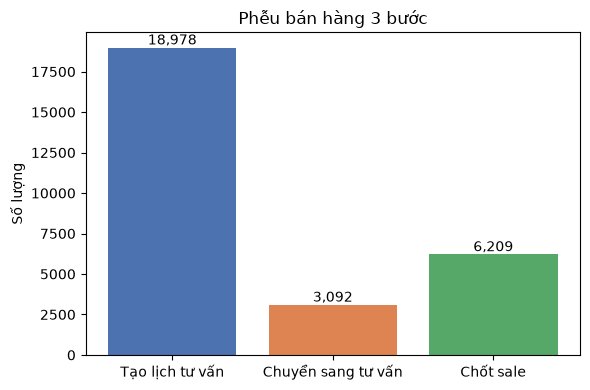

In [6]:
h("CELL 2: BIỂU ĐỒ PHỄU BÁN HÀNG")

buoc = ["Tạo lịch tư vấn", "Chuyển sang tư vấn", "Chốt sale"]
so_luong = [tong_dong, so_da_tu_van, so_da_chot]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(buoc, so_luong, color=["#4C72B0", "#DD8452", "#55A868"])
for index, gia_tri in enumerate(so_luong):
    ax.text(index, gia_tri + 200, f"{gia_tri:,}", ha="center")
ax.set_title("Phễu bán hàng 3 bước")
ax.set_ylabel("Số lượng")
plt.tight_layout()
plt.show()

**Công thức tính:**
- Bước 1 = tổng số dòng; Bước 2 = tổng(`da_tu_van`); Bước 3 = tổng(`da_chot_sale`)
- % chốt không qua tư vấn = số dòng (`da_chot_sale`=1 và `da_tu_van`=0) / tổng số dòng đã chốt × 100

**Insight:**
- Phễu **KHÔNG tuần tự** như thường thấy: trong 6.209 dòng đã chốt, có tới **5.154 dòng (83%) chưa từng có bước "chuyển sang tư vấn"**.
- Điều này cho thấy có ít nhất **2 luồng bán hàng khác nhau**: 1 luồng có tư vấn viên can thiệp, 1 luồng chốt trực tiếp không qua tư vấn (sẽ thấy rõ luồng này tập trung ở đâu tại CELL 3-4).
- Lưu ý: **không nên dùng khái niệm "rơi rụng bước 2→3"** như phễu cổ điển — cần tách 2 luồng trước khi đánh giá hiệu suất tư vấn.


CELL 3: PHÂN BỐ KHÓA HỌC
  Khoa  So_khach  Ti_le_%
Khóa E     11423    65.73
Khóa F      3780    21.75
Khóa A      1084     6.24
Khóa C       922     5.31
Khóa B       133     0.77
Khóa G        22     0.13
Khóa D        14     0.08


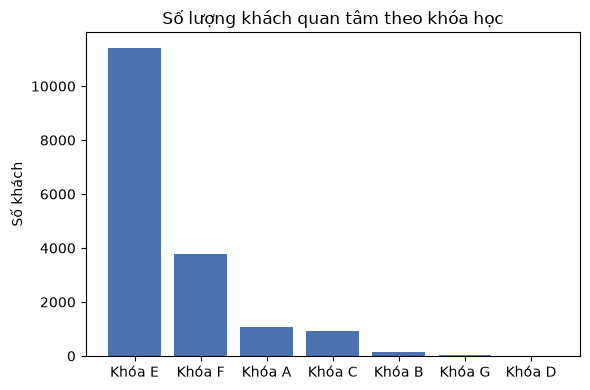

In [7]:
h("CELL 3: PHÂN BỐ KHÓA HỌC")

khoa_sl = df[COL_KHOA].value_counts(dropna=True).reset_index()
khoa_sl.columns = ["Khoa", "So_khach"]
khoa_sl["Ti_le_%"] = (khoa_sl["So_khach"] / khoa_sl["So_khach"].sum() * 100).round(2)
print(khoa_sl.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(khoa_sl["Khoa"], khoa_sl["So_khach"], color="#4C72B0")
ax.set_title("Số lượng khách quan tâm theo khóa học")
ax.set_ylabel("Số khách")
plt.tight_layout()
plt.show()


**Công thức tính:**
- Số khách theo khóa = đếm số dòng theo từng giá trị `quan_tam_khoa_hoc_1` (bỏ dòng rỗng)
- Tỉ lệ % = số khách của 1 khóa / tổng số khách đã xác định khóa (17.378) × 100

**Insight:**
- **Khóa E chiếm 65,73%** tổng nhu cầu (11.423/17.378 khách đã xác định khóa) — là sản phẩm chủ lực áp đảo.
- Khóa F đứng thứ 2 với 21,75%, 5 khóa còn lại (A, B, C, D, G) gộp lại chưa tới 13%.
- → Khóa E gần như chắc chắn chính là luồng "chốt không qua tư vấn" phát hiện ở CELL 2 (sẽ xác nhận thêm ở KPI 1).


CELL 4: HIỆU QUẢ KHÓA HỌC
quan_tam_khoa_hoc_1  so_khach  so_chot  ti_le_chot_%
             Khóa G        22       11         50.00
             Khóa E     11423     4300         37.64
             Khóa C       922      268         29.07
             Khóa F      3780     1057         27.96
             Khóa B       133       12          9.02
             Khóa A      1084       73          6.73
             Khóa D        14        0          0.00


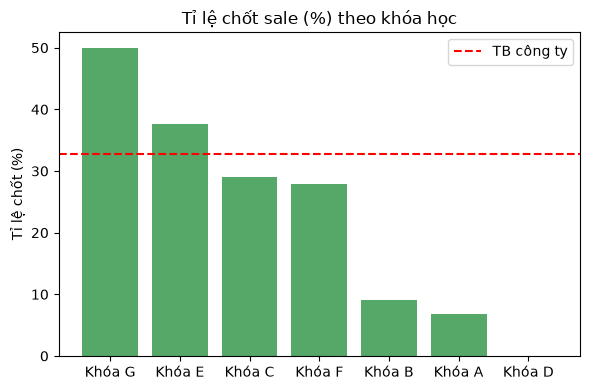

In [8]:
h("CELL 4: HIỆU QUẢ KHÓA HỌC")

khoa_eff = df.groupby(COL_KHOA, dropna=True).agg(
    so_khach=("STT", "count"), so_chot=("da_chot_sale", "sum")
).reset_index()
khoa_eff["ti_le_chot_%"] = (khoa_eff["so_chot"] / khoa_eff["so_khach"] * 100).round(2)
khoa_eff = khoa_eff.sort_values("ti_le_chot_%", ascending=False)
print(khoa_eff.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(khoa_eff[COL_KHOA], khoa_eff["ti_le_chot_%"], color="#55A868")
ax.axhline(df["da_chot_sale"].mean()*100, color="red", linestyle="--", label="TB công ty")
ax.set_title("Tỉ lệ chốt sale (%) theo khóa học")
ax.set_ylabel("Tỉ lệ chốt (%)")
ax.legend()
plt.tight_layout()
plt.show()


**Công thức tính:**
- Tỉ lệ chốt theo khóa (%) = tổng(`da_chot_sale`) trong nhóm khóa đó / tổng số khách nhóm khóa đó × 100 (group theo `quan_tam_khoa_hoc_1`)

**Insight:**
- **Khóa G** có tỉ lệ chốt cao nhất (50%) nhưng mẫu chỉ 22 khách (11 chốt) → **chưa đủ tin cậy** để kết luận chắc chắn, cần thêm dữ liệu.
- **Khóa E** vừa đông nhất vừa hiệu quả cao thứ 2 (37,64%) → mạnh cả về lượng lẫn chất.
- **Khóa A** (1.084 khách) và **Khóa B** (133 khách) có tỉ lệ chốt rất thấp (6,73% và 9,02%) dù lượng khách không nhỏ → đáng lo ngại, cần xem lại giá/kịch bản tư vấn.
- **Khóa D**: 0% chốt trên 14 khách → có vấn đề nghiêm trọng, cần điều tra riêng hoặc cân nhắc dừng.


CELL 5: TOP 10 TƯ VẤN VIÊN NHẬN NHIỀU KHÁCH NHẤT
           tu_van_vien  so_khach  so_chot  ti_le_chot_%
      Trương Thị Huyền      1455      553         38.01
          Bùi Ngọc Anh      1075      259         24.09
           Cao Thảo My      1041      262         25.17
      Hồ Thị Bích Ngọc      1011      311         30.76
           Lê Thị Dung       928      270         29.09
        Lê Thị Thúy Vy       832      282         33.89
Nguyễn Thị Thanh Huyền       810      455         56.17
       Nguyễn Thị Hồng       788      161         20.43
          Phạm Mỹ Linh       748       33          4.41
    Trần Thị Khánh Hòa       738      312         42.28


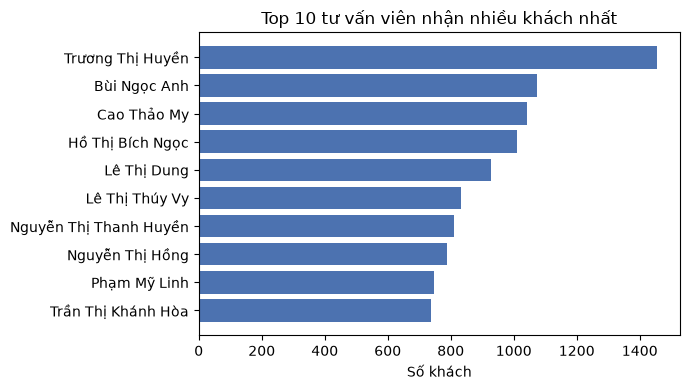

In [9]:
h("CELL 5: TOP 10 TƯ VẤN VIÊN NHẬN NHIỀU KHÁCH NHẤT")

tv_sl = df_tv.groupby(COL_TV).agg(
    so_khach=("STT", "count"), so_chot=("da_chot_sale", "sum")
).reset_index()
tv_sl["ti_le_chot_%"] = (tv_sl["so_chot"] / tv_sl["so_khach"] * 100).round(2)

top10_nhieu = tv_sl.sort_values("so_khach", ascending=False).head(10)
print(top10_nhieu.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top10_nhieu[COL_TV][::-1], top10_nhieu["so_khach"][::-1], color="#4C72B0")
ax.set_title("Top 10 tư vấn viên nhận nhiều khách nhất")
ax.set_xlabel("Số khách")
plt.tight_layout()
plt.show()


**Công thức tính:**
- Số khách theo TV = đếm số dòng theo `tu_van_vien` (đã loại nhãn "Chưa xác định")
- Tỉ lệ chốt (%) = tổng(`da_chot_sale`) / tổng số khách của từng TV × 100

**Insight:**
- **Trương Thị Huyền** nhận nhiều khách nhất (1.455) nhưng tỉ lệ chốt chỉ 38,01% — không phải người hiệu quả nhất.
- **Nguyễn Thị Thanh Huyền** chỉ nhận 810 khách (ít hơn) nhưng tỉ lệ chốt vượt trội **56,17%**.
- **Phạm Mỹ Linh** nhận 748 khách (top 9 về khối lượng) nhưng tỉ lệ chốt chỉ 4,41% — thấp bất thường so với khối lượng được giao.
→ **Workload đang không đi cùng hiệu suất**, xem thêm CELL 6-7.


CELL 6: TOP 10 TƯ VẤN VIÊN TỈ LỆ CHỐT CAO NHẤT (đủ mẫu ≥ 10 khách)
           tu_van_vien  so_khach  so_chot  ti_le_chot_%
 Nguyễn Thị Hồng Nhung        13       10         76.92
          Trần Tố Uyên       486      369         75.93
         Đỗ Bảo Phương       574      375         65.33
        Đinh Thị Nhung       643      368         57.23
Nguyễn Thị Thanh Huyền       810      455         56.17
      Tạ Thị Hoài Ngọc       215      117         54.42
    Nguyễn Thị Mai Anh       690      365         52.90
      Lê Thị Minh Hằng       536      265         49.44
              Ánh Trần       360      171         47.50
          Phạm Thị Thu       448      201         44.87

TB công ty: 32.72%


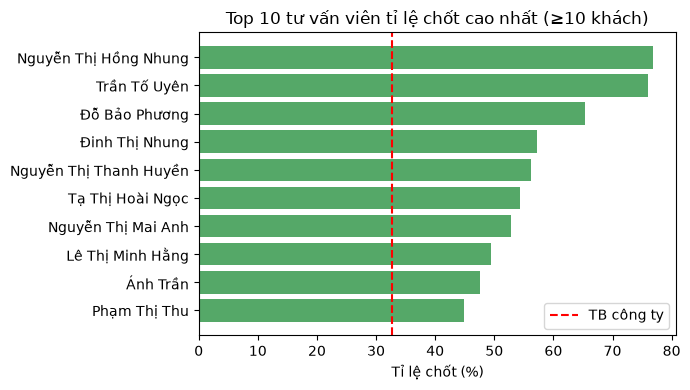

In [10]:
h("CELL 6: TOP 10 TƯ VẤN VIÊN TỈ LỆ CHỐT CAO NHẤT (đủ mẫu ≥ 10 khách)")

tv_du_mau = tv_sl[tv_sl["so_khach"] >= 10]
top10_chot = tv_du_mau.sort_values("ti_le_chot_%", ascending=False).head(10)
print(top10_chot.to_string(index=False))
print(f"\nTB công ty: {df['da_chot_sale'].mean()*100:.2f}%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top10_chot[COL_TV][::-1], top10_chot["ti_le_chot_%"][::-1], color="#55A868")
ax.axvline(df["da_chot_sale"].mean()*100, color="red", linestyle="--", label="TB công ty")
ax.set_title("Top 10 tư vấn viên tỉ lệ chốt cao nhất (≥10 khách)")
ax.set_xlabel("Tỉ lệ chốt (%)")
ax.legend()
plt.tight_layout()
plt.show()


**Công thức tính:**
- Công thức giống CELL 5 (tỉ lệ chốt = tổng chốt / tổng khách × 100 theo từng TV)
- Chỉ lấy TV có số khách ≥ 10 (`so_khach >= 10`), rồi sắp xếp giảm dần theo tỉ lệ chốt

**Insight:**
- Người đứng đầu tỉ lệ chốt (Nguyễn Thị Hồng Nhung, 76,92%) chỉ có **13 khách — mẫu quá nhỏ để tin cậy hoàn toàn**.
- Đáng tin hơn: **Trần Tố Uyên** (486 khách, 75,93%) và **Đỗ Bảo Phương** (574 khách, 65,33%) — mẫu đủ lớn, tỉ lệ chốt gấp đôi TB công ty (32,72%).
→ Đây là ứng viên phù hợp nhất để làm mentor/đào tạo lại nhóm hiệu suất thấp.


CELL 7: 10 TƯ VẤN VIÊN TỈ LỆ CHỐT THẤP NHẤT (đủ mẫu ≥ 10 khách)
        tu_van_vien  so_khach  so_chot  ti_le_chot_%
    Hoàng Ngọc Trúc       138        0          0.00
    Chử Hương Giang        16        0          0.00
  Nguyễn Trọng Vinh        64        0          0.00
   Nguyễn Trung Anh       119        1          0.84
       Phạm Mỹ Linh       748       33          4.41
    Đặng Lê Hồng Ân       126        8          6.35
 Trương Phương Linh       499       33          6.61
    Nguyễn Kim Ngân       476       38          7.98
Trần Thị Minh Sương       199       18          9.05
    Lê Thị Thu Hoài       633       60          9.48

Nhóm này chiếm 3,018 khách (15.9% tổng lead)


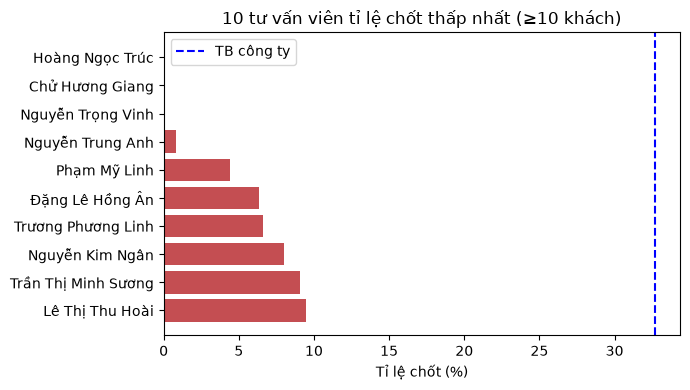

In [11]:
h("CELL 7: 10 TƯ VẤN VIÊN TỈ LỆ CHỐT THẤP NHẤT (đủ mẫu ≥ 10 khách)")

yeu = tv_du_mau.sort_values("ti_le_chot_%").head(10)
print(yeu.to_string(index=False))
print(f"\nNhóm này chiếm {yeu['so_khach'].sum():,} khách "
      f"({yeu['so_khach'].sum()/len(df)*100:.1f}% tổng lead)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(yeu[COL_TV][::-1], yeu["ti_le_chot_%"][::-1], color="#C44E52")
ax.axvline(df["da_chot_sale"].mean()*100, color="blue", linestyle="--", label="TB công ty")
ax.set_title("10 tư vấn viên tỉ lệ chốt thấp nhất (≥10 khách)")
ax.set_xlabel("Tỉ lệ chốt (%)")
ax.legend()
plt.tight_layout()
plt.show()


**Công thức tính:**
- Công thức giống CELL 5/6, chỉ khác là sắp xếp **tăng dần** theo tỉ lệ chốt (lấy 10 TV thấp nhất, vẫn giữ điều kiện ≥10 khách)

**Insight:**
- **3 TV viên có tỉ lệ chốt 0% dù đủ mẫu**: Hoàng Ngọc Trúc (138 khách), Nguyễn Trọng Vinh (64 khách), Chử Hương Giang (16 khách) → cần rà soát gấp.
- Nhóm 10 TV yếu nhất đang cầm **3.018 khách (15,9% tổng lead)** → nếu cải thiện được nhóm này, tiềm năng tăng trưởng đáng kể mà không cần thêm lead mới.


CELL 8: PARETO 80/20 — ĐỘ TẬP TRUNG LEAD
Tổng số TV viên: 55
Số TV viên đảm nhận 80% lead: 19 (34.5% tổng số TV)


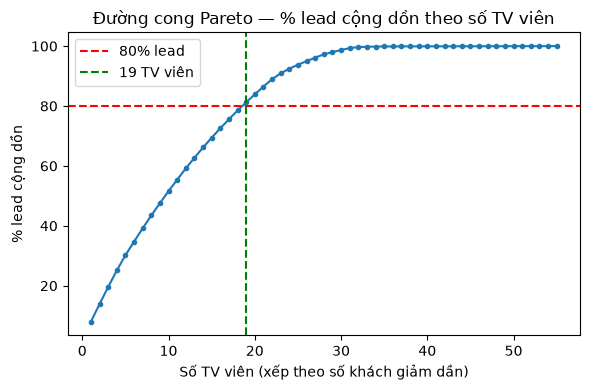

In [12]:
h("CELL 8: PARETO 80/20 — ĐỘ TẬP TRUNG LEAD")

tv_sorted = tv_sl.sort_values("so_khach", ascending=False).copy()
tv_sorted["cum_%"] = tv_sorted["so_khach"].cumsum() / tv_sorted["so_khach"].sum() * 100
n_tv_80 = (tv_sorted["cum_%"] <= 80).sum() + 1
print(f"Tổng số TV viên: {len(tv_sorted)}")
print(f"Số TV viên đảm nhận 80% lead: {n_tv_80} ({n_tv_80/len(tv_sorted)*100:.1f}% tổng số TV)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, len(tv_sorted)+1), tv_sorted["cum_%"].values, marker="o", markersize=3)
ax.axhline(80, color="red", linestyle="--", label="80% lead")
ax.axvline(n_tv_80, color="green", linestyle="--", label=f"{n_tv_80} TV viên")
ax.set_title("Đường cong Pareto — % lead cộng dồn theo số TV viên")
ax.set_xlabel("Số TV viên (xếp theo số khách giảm dần)")
ax.set_ylabel("% lead cộng dồn")
ax.legend()
plt.tight_layout()
plt.show()


**Công thức tính:**
- Sắp xếp TV giảm dần theo `so_khach`
- % lead cộng dồn = cumsum(`so_khach`) / tổng(`so_khach`) × 100 (cumsum: cộng dồn từ TV nhiều khách nhất trở xuống)
- Số TV đạt 80% lead = đếm số dòng có % cộng dồn ≤ 80, rồi +1 (để lấy đúng TV chạm mốc 80%)

**Insight:**
- **19/55 TV viên (34,5%) đảm nhận 80% tổng lead** → độ tập trung khá cao, nhưng chưa tới mức cực đoan kiểu 20/80 cổ điển (nếu đúng vậy chỉ cần ~11 TV).
- Rủi ro: nếu vài người trong nhóm 19 TV này nghỉ việc cùng lúc, ảnh hưởng lớn đến khả năng xử lý lead của cả công ty — nên có kế hoạch dự phòng/đào tạo thêm.


CELL 9: HIỆU QUẢ THEO NHÀ MẠNG
      nha_mang  so_khach  so_chot  ti_le_chot_%
     Vinaphone      3141     1062         33.81
       Viettel     11710     3935         33.60
      Mobifone      2512      804         32.01
          Khác      1613      408         25.29
Không xác định         2        0          0.00


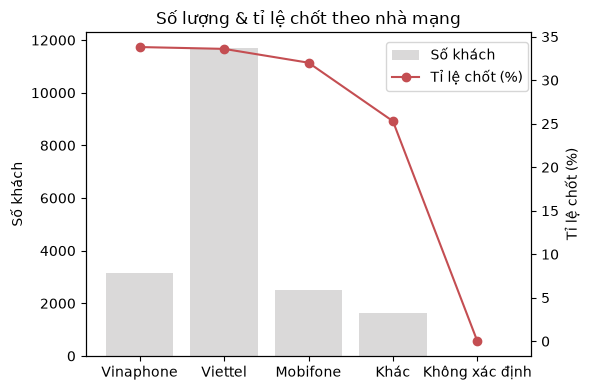

In [13]:
h("CELL 9: HIỆU QUẢ THEO NHÀ MẠNG")

nm = df.groupby(COL_NM).agg(
    so_khach=("STT", "count"), so_chot=("da_chot_sale", "sum")
).reset_index()
nm["ti_le_chot_%"] = (nm["so_chot"] / nm["so_khach"] * 100).round(2)
nm = nm.sort_values("ti_le_chot_%", ascending=False)
print(nm.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.bar(nm[COL_NM], nm["so_khach"], color="#DAD9D9", label="Số khách")
ax1.set_ylabel("Số khách")
ax2 = ax1.twinx()
ax2.plot(nm[COL_NM], nm["ti_le_chot_%"], color="#C44E52", marker="o", label="Tỉ lệ chốt (%)")
ax2.set_ylabel("Tỉ lệ chốt (%)")
ax1.set_title("Số lượng & tỉ lệ chốt theo nhà mạng")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.9))
plt.tight_layout()
plt.show()


**Công thức tính:**
- Tỉ lệ chốt theo nhà mạng (%) = tổng(`da_chot_sale`) / tổng số khách của từng `nha_mang` × 100

**Insight:**
- Vinaphone (33,81%) và Viettel (33,60%) có tỉ lệ chốt cao nhất, khá sát nhau; "Khác" thấp hẳn (25,29%).
- Lưu ý quan trọng: cột `nha_mang` chỉ là **nhà mạng SIM điện thoại**, **KHÔNG PHẢI kênh marketing** (Facebook/Google/TikTok...). Câu hỏi gốc "nền tảng nào được nhiều thành công" **chưa thể trả lời đúng bằng cột này** — đây là **dữ liệu còn thiếu**, cần bên Marketing bổ sung trường nguồn kênh (UTM/source) thì phân tích ở CELL 10 mới thật sự có ý nghĩa với câu hỏi gốc.

In [14]:
h("CELL 10: NHÀ MẠNG VÀ TƯ VẤN VIÊN")

top6_tv = tv_sl.sort_values("so_khach", ascending=False).head(6)[COL_TV].tolist()
pivot = df_tv[df_tv[COL_TV].isin(top6_tv)].pivot_table(
    index=COL_TV,
    columns=COL_NM,
    values="da_chot_sale",
    aggfunc="mean",
).round(3) * 100

print("Tỉ lệ chốt (%) của 6 tư vấn viên theo nhà mạng:")
print(pivot.to_string())


CELL 10: NHÀ MẠNG VÀ TƯ VẤN VIÊN
Tỉ lệ chốt (%) của 6 tư vấn viên theo nhà mạng:
nha_mang          Khác  Mobifone  Viettel  Vinaphone
tu_van_vien                                         
Bùi Ngọc Anh      13.8      12.5     27.6       28.1
Cao Thảo My       18.9      26.1     24.1       30.4
Hồ Thị Bích Ngọc  17.4      23.8     36.0       28.8
Lê Thị Dung       16.4      23.8     29.6       36.7
Lê Thị Thúy Vy    22.1      33.5     36.7       30.4
Trương Thị Huyền  44.7      48.5     32.6       37.3



CELL 10: BIỂU ĐỒ TỈ LỆ CHỐT


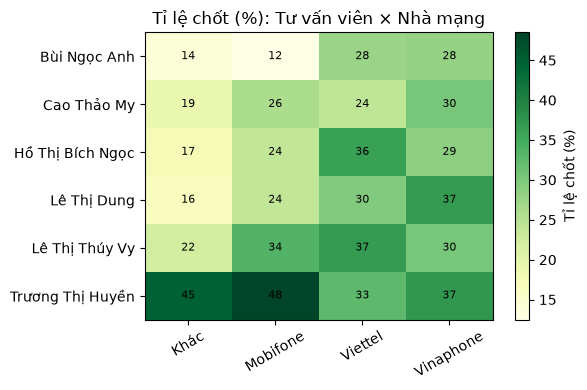

In [15]:
h("CELL 10: BIỂU ĐỒ TỈ LỆ CHỐT")

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(pivot.values, cmap="YlGn", aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=30)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)

for row_index in range(pivot.shape[0]):
    for column_index in range(pivot.shape[1]):
        value = pivot.values[row_index, column_index]
        if not np.isnan(value):
            ax.text(column_index, row_index, f"{value:.0f}", ha="center", va="center", fontsize=8)

ax.set_title("Tỉ lệ chốt (%): Tư vấn viên × Nhà mạng")
plt.colorbar(im, ax=ax, label="Tỉ lệ chốt (%)")
plt.tight_layout()
plt.show()

**Công thức tính:**
- Với mỗi ô (TV viên × nhà mạng): tỉ lệ chốt (%) = mean(`da_chot_sale`) của các dòng thuộc đúng TV viên đó VÀ đúng nhà mạng đó × 100 (dùng `pivot_table`, `aggfunc="mean"`)
- Chỉ tính cho Top 6 TV viên nhận nhiều khách nhất (lấy từ CELL 5)

**Insight:**
- Biến thiên tỉ lệ chốt **giữa các TV viên trong CÙNG 1 nhà mạng** khá lớn: ở Mobifone dao động từ 12,5% (Bùi Ngọc Anh) đến 48,5% (Trương Thị Huyền).
- Biến thiên **theo từng TV viên qua các nhà mạng khác nhau** cũng đáng kể (Trương Thị Huyền: 32,6%–48,5%) nhưng không rõ ràng lớn hơn hẳn biến thiên theo nhà mạng.
→ **Chưa đủ căn cứ khẳng định dứt khoát** "do kênh tốt" hay "do nhân viên nhiệt tình" — hai yếu tố đan xen. Và như lưu ý ở CELL 9, đây mới là nhà mạng SIM chứ chưa phải kênh MKT thật, nên kết luận cuối cùng cần đợi dữ liệu nguồn kênh chuẩn.


CELL 11: SENTIMENT vs CHỐT SALE
sentimatic  so_khach  so_chot  ti_le_chot_%
   unknown      6509     2376         36.50
  tieu_cuc      7319     2257         30.84
  tich_cuc      5150     1576         30.60


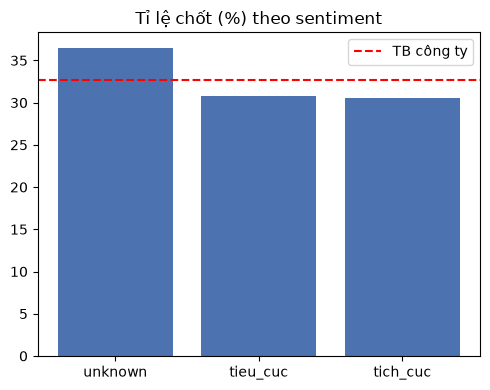

In [16]:
h("CELL 11: SENTIMENT vs CHỐT SALE")

sent = df.groupby(COL_SENT).agg(
    so_khach=("STT", "count"), so_chot=("da_chot_sale", "sum")
).reset_index()
sent["ti_le_chot_%"] = (sent["so_chot"] / sent["so_khach"] * 100).round(2)
sent = sent.sort_values("ti_le_chot_%", ascending=False)
print(sent.to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(sent[COL_SENT], sent["ti_le_chot_%"], color="#4C72B0")
ax.axhline(df["da_chot_sale"].mean()*100, color="red", linestyle="--", label="TB công ty")
ax.set_title("Tỉ lệ chốt (%) theo sentiment")
ax.legend()
plt.tight_layout()
plt.show()


**Công thức tính:**
- Tỉ lệ chốt theo sentiment (%) = tổng(`da_chot_sale`) / tổng số khách của từng `sentimatic` × 100

**Insight:**
- Bất ngờ: nhóm **"unknown"** (chưa xác định cảm xúc, 6.509 khách) có tỉ lệ chốt **CAO NHẤT (36,50%)** — cao hơn cả "tích cực" (30,60%) và "tiêu cực" (30,84%).
- "Tích cực" và "tiêu cực" gần như **không khác biệt** (30,60% vs 30,84%) → sentiment hiện tại **không phải yếu tố dự báo tốt** cho khả năng chốt sale.
- Chưa đủ căn cứ để giải thích vì sao — có thể do `sentimatic` được tư vấn viên gán **thủ công, chủ quan**, hoặc nhóm "unknown" trùng nhiều với Khóa E (luồng bán không qua tư vấn nên không ai gán cảm xúc). Cần nghiệp vụ CSKH xác nhận lại quy trình gán nhãn sentiment.


CELL 12: MỨC ĐỘ CHĂM SÓC vs CHỐT SALE
 MKT_xu_ly_data  so_khach  so_chot  ti_le_chot_%
        Thu hồi      1403      515         36.71
Chăm sóc vòng 1     13026     4623         35.49
    Điều chuyển        69       18         26.09
Chăm sóc vòng 2       730      168         23.01

Số dòng không ghi nhận mức chăm sóc: 3750 (19.8%)


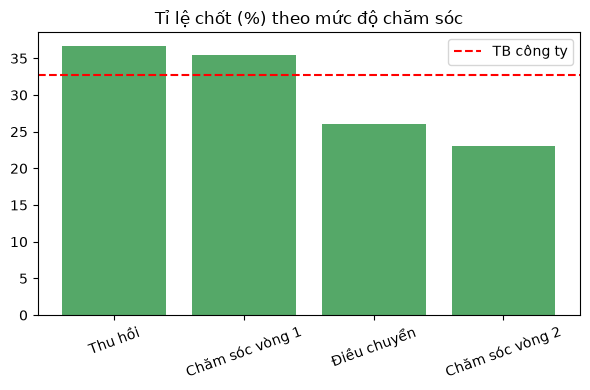

In [17]:
h("CELL 12: MỨC ĐỘ CHĂM SÓC vs CHỐT SALE")

mkt = df.groupby(COL_MKT, dropna=True).agg(
    so_khach=("STT", "count"), so_chot=("da_chot_sale", "sum")
).reset_index()
mkt["ti_le_chot_%"] = (mkt["so_chot"] / mkt["so_khach"] * 100).round(2)
mkt = mkt.sort_values("ti_le_chot_%", ascending=False)
print(mkt.to_string(index=False))
print(f"\nSố dòng không ghi nhận mức chăm sóc: {df[COL_MKT].isna().sum()} "
      f"({df[COL_MKT].isna().sum()/len(df)*100:.1f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(mkt[COL_MKT], mkt["ti_le_chot_%"], color="#55A868")
ax.axhline(df["da_chot_sale"].mean()*100, color="red", linestyle="--", label="TB công ty")
ax.set_title("Tỉ lệ chốt (%) theo mức độ chăm sóc")
plt.xticks(rotation=20)
ax.legend()
plt.tight_layout()
plt.show()


**Công thức tính:**
- Tỉ lệ chốt theo mức chăm sóc (%) = tổng(`da_chot_sale`) / tổng số khách của từng `MKT_xu_ly_data` × 100 (bỏ dòng rỗng)

**Insight:**
- "Thu hồi" (36,71%) và "Chăm sóc vòng 1" (35,49%) có tỉ lệ chốt cao nhất — **ngược với giả thuyết ban đầu** rằng chăm sóc nhiều vòng mới hiệu quả.
- "Chăm sóc vòng 2" tỉ lệ chốt lại **thấp hơn** (23,01%) — có thể do đây là nhóm khách khó tính đã từ chối ở vòng 1, không hẳn do chăm sóc vòng 2 kém hiệu quả (cần thêm dữ liệu để phân biệt 2 khả năng này).
- Lưu ý: **3.750 dòng (19,8% — gần 1/5 dữ liệu) không ghi nhận mức chăm sóc** → hạn chế đáng kể khi diễn giải kết quả trên.

In [18]:
h("CELL 13: THỜI GIAN TỪ TƯ VẤN ĐẾN CHỐT")

df_chot = df[(df["da_chot_sale"] == 1) & df[COL_NGAY].notna()].copy()
df_chot["bucket"] = pd.cut(
    df_chot[COL_NGAY],
    bins=[-1, 1, 3, 7, 14, 30, 999],
    labels=["≤1 ngày", "2-3 ngày", "4-7 ngày", "8-14 ngày", "15-30 ngày", ">30 ngày"],
)
bucket = df_chot.groupby("bucket", observed=True).agg(
    so_chot=("STT", "count")
).reset_index()
bucket["Ti_le_%"] = (bucket["so_chot"] / len(df_chot) * 100).round(2)

print(bucket.to_string(index=False))
print(f"Có thời gian hợp lệ: {len(df_chot):,} / {so_da_chot:,} ca chốt")
print(f"Số ngày trung bình: {df_chot[COL_NGAY].mean():.2f}")


CELL 13: THỜI GIAN TỪ TƯ VẤN ĐẾN CHỐT
    bucket  so_chot  Ti_le_%
   ≤1 ngày      134    15.04
  2-3 ngày       30     3.37
  4-7 ngày       79     8.87
 8-14 ngày      135    15.15
15-30 ngày      224    25.14
  >30 ngày      289    32.44
Có thời gian hợp lệ: 891 / 6,209 ca chốt
Số ngày trung bình: 29.74



CELL 13: BIỂU ĐỒ THỜI GIAN CHỐT


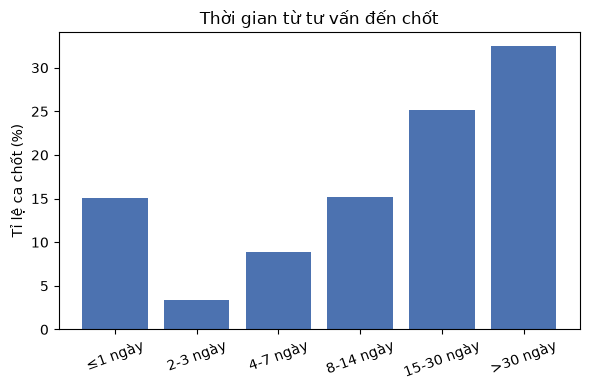

In [19]:
h("CELL 13: BIỂU ĐỒ THỜI GIAN CHỐT")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(bucket["bucket"].astype(str), bucket["Ti_le_%"], color="#4C72B0")
ax.set_title("Thời gian từ tư vấn đến chốt")
ax.set_ylabel("Tỉ lệ ca chốt (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Công thức tính:**
- `so_ngay_tu_van_den_chot` = số ngày giữa `thoi_gian_chuyen_sang_chot_sale` và `thoi_gian_chuyen_sang_tu_van` (đã tính sẵn từ file xử lý trước, giá trị âm đã được loại)
- Chia nhóm (bucket) theo mốc ngày: `pd.cut(bins=[-1, 1, 3, 7, 14, 30, 999])`
- % mỗi nhóm = số ca trong nhóm / tổng số ca **có dữ liệu hợp lệ** (891 dòng) × 100 — không phải trên tổng 6.209 dòng đã chốt

**Insight:**
- Chỉ **891/6.209 dòng đã chốt (14,4%) có đủ dữ liệu thời gian tư vấn hợp lệ** để tính tốc độ xử lý — khớp với phát hiện ở CELL 2 rằng phần lớn case chốt không qua tư vấn nên không có mốc thời gian này.
- Trong nhóm ít ỏi có dữ liệu, xu hướng đi **ngược kỳ vọng "chốt nhanh là tốt"**: chỉ 15,04% chốt trong ≤1 ngày, còn 32,44% chốt sau hơn 30 ngày, TB tới 29,74 ngày mới chốt.
- Chưa đủ căn cứ để kết luận "cần phản hồi nhanh" như thường thấy ở các mô hình sale khác — vì mẫu quá nhỏ và không đại diện cho phần lớn (83%) case chốt qua luồng khác.


CELL 14: XU HƯỚNG THEO THÁNG
thang_dang_ky  so_lead  so_chot  ti_le_chot_%
      2023-12       21        0          0.00
      2024-01     1093       63          5.76
      2024-02      615       42          6.83
      2024-03     1529      138          9.03
      2024-04     1982      284         14.33
      2024-05     2818      971         34.46
      2024-06     3494     1690         48.37
      2024-07     3203     1467         45.80
      2024-08     1938      807         41.64
      2024-09      656      245         37.35
      2024-10      769      309         40.18
      2024-11      814      192         23.59
      2024-12       45        1          2.22


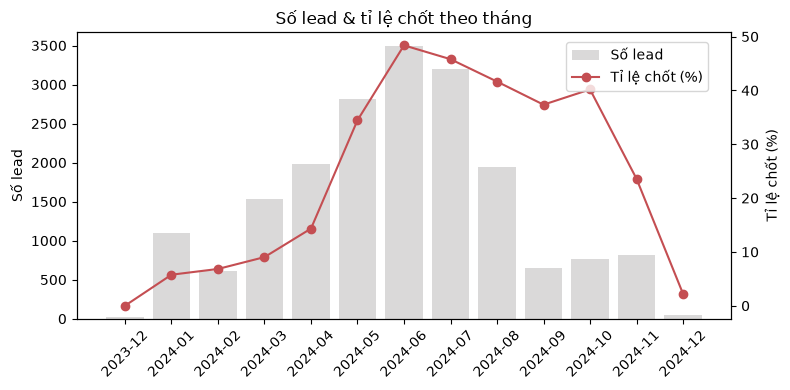

In [20]:
h("CELL 14: XU HƯỚNG THEO THÁNG")

trend = df.groupby("thang_dang_ky").agg(
    so_lead=("STT", "count"), so_chot=("da_chot_sale", "sum")
).reset_index().sort_values("thang_dang_ky")
trend["ti_le_chot_%"] = (trend["so_chot"] / trend["so_lead"] * 100).round(2)
print(trend.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(trend["thang_dang_ky"], trend["so_lead"], color="#DAD9D9", label="Số lead")
ax1.set_ylabel("Số lead")
plt.xticks(rotation=45)
ax2 = ax1.twinx()
ax2.plot(trend["thang_dang_ky"], trend["ti_le_chot_%"], color="#C44E52", marker="o", label="Tỉ lệ chốt (%)")
ax2.set_ylabel("Tỉ lệ chốt (%)")
ax1.set_title("Số lead & tỉ lệ chốt theo tháng")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.9))
plt.tight_layout()
plt.show()


**Công thức tính:**
- Group theo `thang_dang_ky` (tháng của `ngay_tao`)
- Tỉ lệ chốt theo tháng (%) = tổng(`da_chot_sale`) / tổng số lead của tháng đó × 100

**Insight:**
- Lead và tỉ lệ chốt tăng rất mạnh từ đầu đến giữa năm 2024: tỉ lệ chốt từ **5,76% (T1) vọt lên 48,37% (T6)**, rồi giảm dần cuối năm (T11 còn 23,59%).
- Tháng 6-7/2024 là đỉnh điểm cả về lượng lead (3.494 và 3.203) lẫn tỉ lệ chốt.
- Lưu ý: dữ liệu chỉ đủ 1 năm (12/2023 – 12/2024) nên chưa đủ căn cứ kết luận đây có phải quy luật mùa vụ lặp lại hàng năm hay chỉ là xu hướng tăng trưởng nhất thời — cần thêm dữ liệu nhiều năm.


CELL 15: PHÂN BỐ THEO GIỜ ĐĂNG KÝ
 gio_dang_ky  so_lead  so_chot  ti_le_chot_%
         0.0       25        9         36.00
         1.0        4        2         50.00
         6.0        3        2         66.67
         7.0       94       32         34.04
         8.0     3221     1143         35.49
         9.0     3804     1285         33.78
        10.0     1977      653         33.03
        11.0     1526      457         29.95
        12.0      218       47         21.56
        13.0     1415      506         35.76
        14.0     2084      588         28.21
        15.0     1509      502         33.27
        16.0     1448      468         32.32
        17.0      933      288         30.87
        18.0      131       35         26.72
        19.0       83       31         37.35
        20.0      141       32         22.70
        21.0      171       62         36.26
        22.0       95       30         31.58
        23.0       95       37         38.95


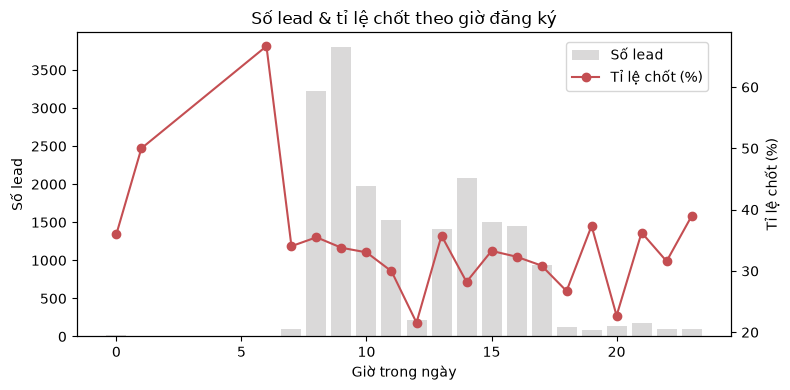

In [21]:
h("CELL 15: PHÂN BỐ THEO GIỜ ĐĂNG KÝ")

gio = df.groupby("gio_dang_ky").agg(
    so_lead=("STT", "count"), so_chot=("da_chot_sale", "sum")
).reset_index()
gio["ti_le_chot_%"] = (gio["so_chot"] / gio["so_lead"] * 100).round(2)
print(gio.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(gio["gio_dang_ky"], gio["so_lead"], color="#DAD9D9", label="Số lead")
ax1.set_xlabel("Giờ trong ngày"); ax1.set_ylabel("Số lead")
ax2 = ax1.twinx()
ax2.plot(gio["gio_dang_ky"], gio["ti_le_chot_%"], color="#C44E52", marker="o", label="Tỉ lệ chốt (%)")
ax2.set_ylabel("Tỉ lệ chốt (%)")
ax1.set_title("Số lead & tỉ lệ chốt theo giờ đăng ký")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.9))
plt.tight_layout()
plt.show()


**Công thức tính:**
- Group theo `gio_dang_ky` (giờ trích từ `ngay_tao`)
- Tỉ lệ chốt theo giờ (%) = tổng(`da_chot_sale`) / tổng số lead của giờ đó × 100

**Insight:**
- Giờ 8-10h có lượng lead cao nhất (3.221–3.804 lead/giờ), nhưng tỉ lệ chốt khá **đồng đều** quanh 30-36% ở hầu hết khung giờ có mẫu đủ lớn.
- Vài khung giờ ít lead (0h, 1h, 6h) có tỉ lệ chốt vọt cao (36-66,7%) nhưng mẫu chỉ 3-25 khách → **không đủ tin cậy**, nhiều khả năng là nhiễu thống kê chứ không phải xu hướng thật.


CELL 16: PHÂN BỐ THEO NGÀY TRONG TUẦN
Thu  so_lead  so_chot  ti_le_chot_%
 T2     3357     1091         32.50
 T3     2873      959         33.38
 T4     2671      882         33.02
 T5     2943      877         29.80
 T6     2970      931         31.35
 T7     2103      727         34.57
 CN     2060      742         36.02


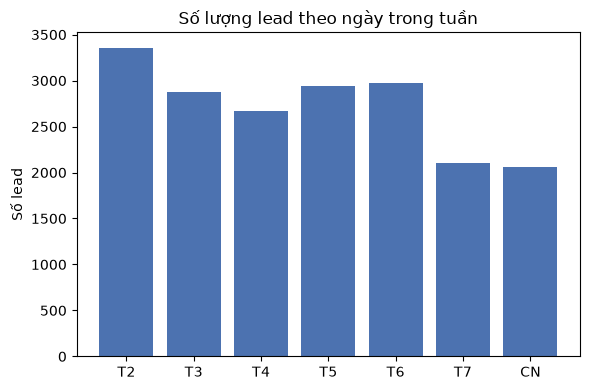

In [22]:
h("CELL 16: PHÂN BỐ THEO NGÀY TRONG TUẦN")

thu_map = {0:"T2",1:"T3",2:"T4",3:"T5",4:"T6",5:"T7",6:"CN"}
thu = df.groupby("thu_dang_ky").agg(
    so_lead=("STT", "count"), so_chot=("da_chot_sale", "sum")
).reset_index()
thu["Thu"] = thu["thu_dang_ky"].map(thu_map)
thu["ti_le_chot_%"] = (thu["so_chot"] / thu["so_lead"] * 100).round(2)
print(thu[["Thu", "so_lead", "so_chot", "ti_le_chot_%"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(thu["Thu"], thu["so_lead"], color="#4C72B0")
ax.set_title("Số lượng lead theo ngày trong tuần")
ax.set_ylabel("Số lead")
plt.tight_layout()
plt.show()


**Công thức tính:**
- Group theo `thu_dang_ky` (thứ trong tuần, 0=T2...6=CN, trích từ `ngay_tao`)
- Tỉ lệ chốt theo thứ (%) = tổng(`da_chot_sale`) / tổng số lead của thứ đó × 100

**Insight:**
- Số lead cao nhất vào Thứ 2 (3.357), thấp nhất vào Thứ 7/Chủ nhật (~2.060-2.103).
- Nhưng tỉ lệ chốt lại **cao nhất vào Chủ nhật (36,02%)** dù lead ít nhất — ngược hướng với lượng lead, gợi ý khách đăng ký cuối tuần có thể "chín" hơn dù ít hơn về số lượng.


CELL 17: GIỜ HÀNH CHÍNH (8-17H) vs NGOÀI GIỜ
      Nhan  so_khach  so_chot  ti_le_chot_%
 Ngoài giờ       843      272         32.27
Hành chính     18135     5937         32.74


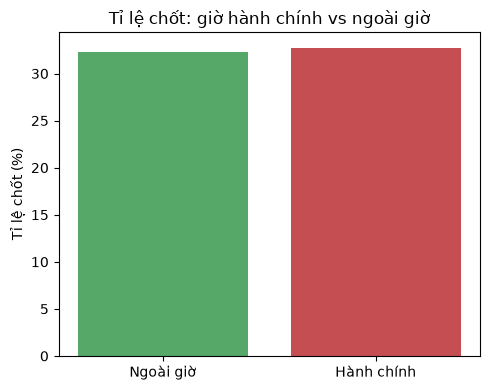

In [23]:
h("CELL 17: GIỜ HÀNH CHÍNH (8-17H) vs NGOÀI GIỜ")

hc = df.groupby("la_gio_hanh_chinh").agg(
    so_khach=("STT", "count"), so_chot=("da_chot_sale", "sum")
).reset_index()
hc["Nhan"] = hc["la_gio_hanh_chinh"].map({0: "Ngoài giờ", 1: "Hành chính"})
hc["ti_le_chot_%"] = (hc["so_chot"] / hc["so_khach"] * 100).round(2)
print(hc[["Nhan", "so_khach", "so_chot", "ti_le_chot_%"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(hc["Nhan"], hc["ti_le_chot_%"], color=["#55A868", "#C44E52"])
ax.set_title("Tỉ lệ chốt: giờ hành chính vs ngoài giờ")
ax.set_ylabel("Tỉ lệ chốt (%)")
plt.tight_layout()
plt.show()


**Công thức tính:**
- `la_gio_hanh_chinh` = 1 nếu `gio_dang_ky` nằm trong khoảng [8, 17], ngược lại 0
- Tỉ lệ chốt (%) = tổng(`da_chot_sale`) / tổng số khách của mỗi nhóm (hành chính / ngoài giờ) × 100

**Insight:**
- Giờ hành chính (32,74%) và ngoài giờ (32,27%) **gần như không khác biệt** về tỉ lệ chốt → chưa có bằng chứng cần mở rộng ca trực ngoài giờ hoặc khách hàng có đặc thù giờ giấc riêng.

In [24]:
h("CELL 18: KHÓA HỌC VÀ SENTIMENT")

cross_ks = df.pivot_table(
    index=COL_KHOA,
    columns=COL_SENT,
    values="da_chot_sale",
    aggfunc="mean",
).round(3) * 100

print("Tỉ lệ chốt (%) theo khóa học và sentiment:")
print(cross_ks.to_string())


CELL 18: KHÓA HỌC VÀ SENTIMENT
Tỉ lệ chốt (%) theo khóa học và sentiment:
sentimatic           tich_cuc  tieu_cuc  unknown
quan_tam_khoa_hoc_1                             
Khóa A                    6.3       5.6     10.8
Khóa B                    9.3       7.4     11.1
Khóa C                   30.3      29.6     21.0
Khóa D                    0.0       0.0      0.0
Khóa E                   35.9      36.2     39.8
Khóa F                   26.0      26.9     31.6
Khóa G                   41.7      50.0     75.0



CELL 18: BIỂU ĐỒ KHÓA HỌC VÀ SENTIMENT


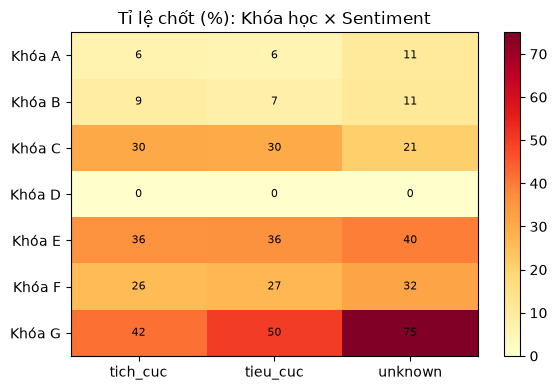

In [25]:
h("CELL 18: BIỂU ĐỒ KHÓA HỌC VÀ SENTIMENT")

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(cross_ks.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(cross_ks.columns)))
ax.set_xticklabels(cross_ks.columns)
ax.set_yticks(range(len(cross_ks.index)))
ax.set_yticklabels(cross_ks.index)

for row_index in range(cross_ks.shape[0]):
    for column_index in range(cross_ks.shape[1]):
        value = cross_ks.values[row_index, column_index]
        if not np.isnan(value):
            ax.text(column_index, row_index, f"{value:.0f}", ha="center", va="center", fontsize=8)

ax.set_title("Tỉ lệ chốt (%): Khóa học × Sentiment")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

**Công thức tính:**
- Với mỗi ô (khóa × sentiment): tỉ lệ chốt (%) = mean(`da_chot_sale`) của các dòng thuộc đúng khóa đó VÀ đúng sentiment đó × 100 (`pivot_table`, `aggfunc="mean"`)

**Insight:**
- Với Khóa E và Khóa G, nhóm "unknown" sentiment vẫn có tỉ lệ chốt **cao nhất** (39,8% và 75%) — củng cố nghi vấn ở CELL 11 rằng "unknown" không phải ngẫu nhiên.
- Khóa D 0% chốt ở **mọi mức sentiment** → xác nhận vấn đề nằm ở bản thân khóa học/sản phẩm, không liên quan đến cảm xúc khách hàng.

In [26]:
h("CELL 19: NHÀ MẠNG × KHÓA HỌC")

cross_nk = df.pivot_table(
    index=COL_NM, columns=COL_KHOA, values="da_chot_sale", aggfunc="mean"
).round(3) * 100
print("Tỉ lệ chốt (%) theo Nhà mạng × Khóa:")
print(cross_nk.to_string())



CELL 19: NHÀ MẠNG × KHÓA HỌC
Tỉ lệ chốt (%) theo Nhà mạng × Khóa:
quan_tam_khoa_hoc_1  Khóa A  Khóa B  Khóa C  Khóa D  Khóa E  Khóa F  Khóa G
nha_mang                                                                   
Khác                    5.3    17.6    29.0     NaN    32.6    22.9    66.7
Mobifone                2.8     6.7    30.8     0.0    36.2    32.9    33.3
Viettel                 8.1     9.3    28.1     0.0    38.1    27.7    63.6
Vinaphone               6.6     0.0    26.2     0.0    38.0    27.6     0.0


**Công thức tính:**
- Với mỗi ô (nhà mạng × khóa): tỉ lệ chốt (%) = mean(`da_chot_sale`) của các dòng thuộc đúng nhà mạng đó VÀ đúng khóa đó × 100 (`pivot_table`, `aggfunc="mean"`)

**Insight:**
- Khóa E chốt tốt và khá ổn định ở mọi nhà mạng (32,6%-38,1%) — sản phẩm mạnh, không phụ thuộc vào nhà mạng khách dùng.
- Một vài ô có giá trị 0% hoặc NaN (Khóa D, Khóa B ở Vinaphone...) — **cần xem cỡ mẫu từng ô trước khi kết luận** vì rất có thể mẫu quá nhỏ, không tính riêng ở bảng này.


CELL 20: ĐIỂM QUAN TÂM TỔNG HỢP
 diem_quan_tam  so_khach  so_chot  ti_le_chot_%
             0     10161     3415         33.61
             1      7247     2270         31.32
             2      1513      510         33.71
             3        57       14         24.56


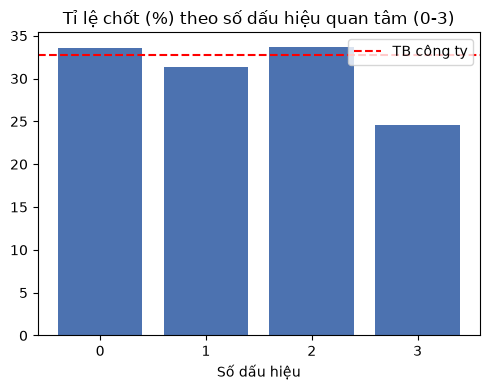

In [27]:
h("CELL 20: ĐIỂM QUAN TÂM TỔNG HỢP")

df["diem_quan_tam"] = (
    (df[COL_SENT] == "tich_cuc").astype(int)
    + df["da_tu_van"]
    + (df[COL_MKT].notna() & (df[COL_MKT] != "Chăm sóc vòng 1")).astype(int)
)
qt = df.groupby("diem_quan_tam").agg(
    so_khach=("STT", "count"), so_chot=("da_chot_sale", "sum")
).reset_index()
qt["ti_le_chot_%"] = (qt["so_chot"] / qt["so_khach"] * 100).round(2)
print(qt.to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(qt["diem_quan_tam"].astype(str), qt["ti_le_chot_%"], color="#4C72B0")
ax.axhline(df["da_chot_sale"].mean()*100, color="red", linestyle="--", label="TB công ty")
ax.set_title("Tỉ lệ chốt (%) theo số dấu hiệu quan tâm (0-3)")
ax.set_xlabel("Số dấu hiệu"); ax.legend()
plt.tight_layout()
plt.show()


**Công thức tính:**
- `diem_quan_tam` = (`sentimatic`=="tich_cuc" ? 1 : 0) + `da_tu_van` + (`MKT_xu_ly_data` khác rỗng VÀ khác "Chăm sóc vòng 1" ? 1 : 0) → điểm chạy từ 0 đến 3
- Tỉ lệ chốt theo từng mức điểm (%) = tổng(`da_chot_sale`) / tổng số khách ở mức điểm đó × 100

**Insight:**
- Số dấu hiệu **không** tỉ lệ thuận với khả năng chốt như giả thuyết ban đầu: 0 dấu hiệu → 33,61%, còn đủ 3/3 dấu hiệu → chỉ **24,56% (thấp nhất!)**.
- Tuy nhiên nhóm 3/3 dấu hiệu chỉ có **57 khách — mẫu rất nhỏ**, nên chưa vội kết luận 3 dấu hiệu này "phản tác dụng", mà nên hiểu là **3 dấu hiệu hiện tại chưa đủ mạnh để làm thước đo** (xem thêm KPI 3).

In [28]:
h("CELL 21: KPI 1 - KHÓA HỌC TIỀM NĂNG")

kpi1 = khoa_eff.copy()
kpi1["diem_nhu_cau"] = (
    (kpi1["so_khach"] - kpi1["so_khach"].min())
    / (kpi1["so_khach"].max() - kpi1["so_khach"].min())
)
kpi1["diem_hieu_qua"] = (
    (kpi1["ti_le_chot_%"] - kpi1["ti_le_chot_%"].min())
    / (kpi1["ti_le_chot_%"].max() - kpi1["ti_le_chot_%"].min())
)
kpi1["diem_tiem_nang"] = (
    (kpi1["diem_nhu_cau"] + kpi1["diem_hieu_qua"]) / 2
).round(3)
kpi1 = kpi1.sort_values("diem_tiem_nang", ascending=False)
print(kpi1[[COL_KHOA, "so_khach", "ti_le_chot_%", "diem_tiem_nang"]].to_string(index=False))


CELL 21: KPI 1 - KHÓA HỌC TIỀM NĂNG
quan_tam_khoa_hoc_1  so_khach  ti_le_chot_%  diem_tiem_nang
             Khóa E     11423         37.64           0.876
             Khóa G        22         50.00           0.500
             Khóa F      3780         27.96           0.445
             Khóa C       922         29.07           0.330
             Khóa A      1084          6.73           0.114
             Khóa B       133          9.02           0.095
             Khóa D        14          0.00           0.000



CELL 21: BIỂU ĐỒ KPI 1


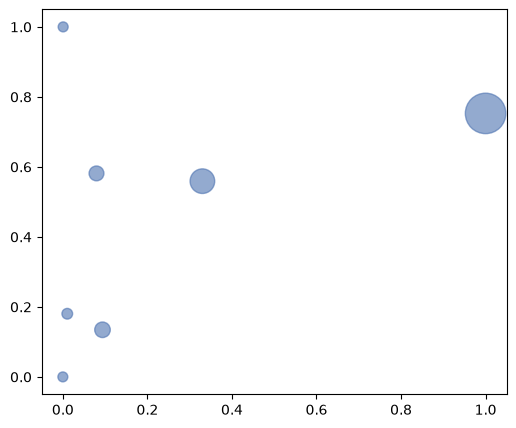

In [29]:
h("CELL 21: BIỂU ĐỒ KPI 1")

fig, ax = plt.subplots(figsize=(6, 5))
sizes = (kpi1["so_khach"] / kpi1["so_khach"].max() * 800) + 50
ax.scatter(
    kpi1["diem_nhu_cau"],
    kpi1["diem_hieu_qua"],
    s=sizes,
    alpha=0.6,
    color="#4C72B0",
)

In [30]:
h("CELL 21: GHI NHÃN VÀ HOÀN THIỆN BIỂU ĐỒ")

for index in range(len(kpi1)):
    khoa = kpi1.iloc[index]
    ax.annotate(
        khoa[COL_KHOA],
        (khoa["diem_nhu_cau"], khoa["diem_hieu_qua"]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

ax.set_xlabel("Điểm nhu cầu")
ax.set_ylabel("Điểm hiệu quả")
ax.set_title("Nhu cầu và hiệu quả theo khóa học")
plt.tight_layout()
plt.show()


CELL 21: GHI NHÃN VÀ HOÀN THIỆN BIỂU ĐỒ


<Figure size 640x480 with 0 Axes>

**Công thức tính:**
- `diem_nhu_cau` = (`so_khach` − min(`so_khach`)) / (max(`so_khach`) − min(`so_khach`)) — chuẩn hóa về [0,1] (Min-Max Scaling)
- `diem_hieu_qua` = (`ti_le_chot_%` − min) / (max − min) — chuẩn hóa tương tự
- `diem_tiem_nang` = `diem_nhu_cau` × 0,5 + `diem_hieu_qua` × 0,5 (trọng số 50/50 giữa nhu cầu và hiệu quả)

**Insight (KPI 1 — kết luận có căn cứ rõ ràng):**
- **Khóa E** là lựa chọn rõ ràng nhất để ưu tiên đầu tư — điểm tiềm năng 0,876, vượt trội hẳn các khóa còn lại (khóa xếp 2 chỉ đạt 0,5).
- **Khóa G (AI)** là "ngách" đáng chú ý (tỉ lệ chốt 50%) nhưng mẫu quá nhỏ (22 khách) để đầu tư mạnh ngay — nên thử nghiệm thêm MKT quy mô nhỏ trước.
- **Khóa D** nên được điều tra riêng hoặc cân nhắc dừng do 0% chốt tuyệt đối.
- Còn thiếu: bảng này mới tính trên nhu cầu + tỉ lệ chốt, **chưa có doanh thu/chi phí MKT từng khóa** → chưa phải ROI thực, cần Tài chính/Marketing bổ sung.

In [31]:
h("CELL 22: KPI 2 - ĐẶC ĐIỂM LEAD")

def dac_diem(nhom):
    return {
        "Số lượng": len(nhom),
        "% sentiment tích cực": (nhom[COL_SENT] == "tich_cuc").mean() * 100,
        "% đã chuyển sang tư vấn": nhom["da_tu_van"].mean() * 100,
        "% chăm sóc từ vòng 2+": (
            nhom[COL_MKT].notna() & (nhom[COL_MKT] != "Chăm sóc vòng 1")
        ).mean() * 100,
    }

kpi2 = pd.DataFrame({
    "Đã chốt sale": dac_diem(df[df["da_chot_sale"] == 1]),
    "Chưa chốt sale": dac_diem(df[df["da_chot_sale"] == 0]),
}).round(2)
kpi2["Chênh lệch"] = (
    kpi2["Đã chốt sale"] - kpi2["Chưa chốt sale"]
).round(2)
print(kpi2.to_string())


CELL 22: KPI 2 - ĐẶC ĐIỂM LEAD
                         Đã chốt sale  Chưa chốt sale  Chênh lệch
Số lượng                      6209.00        12769.00    -6560.00
% sentiment tích cực            25.38           27.99       -2.61
% đã chuyển sang tư vấn         16.99           15.95        1.04
% chăm sóc từ vòng 2+           11.29           11.76       -0.47



CELL 22: BIỂU ĐỒ KPI 2


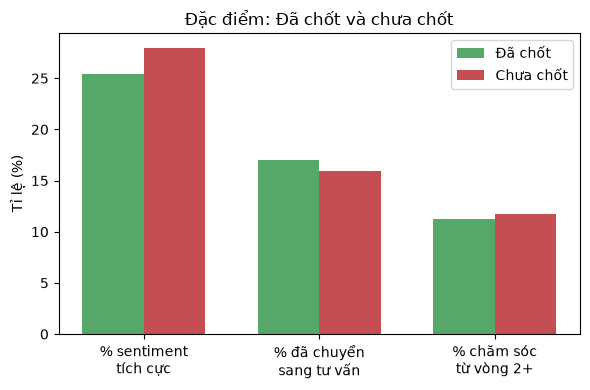

In [32]:
h("CELL 22: BIỂU ĐỒ KPI 2")

chi_so = ["% sentiment tích cực", "% đã chuyển sang tư vấn", "% chăm sóc từ vòng 2+"]
ten_chi_so = ["% sentiment\ntích cực", "% đã chuyển\nsang tư vấn", "% chăm sóc\ntừ vòng 2+"]
x = np.arange(len(chi_so))
rong = 0.35

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x - rong / 2, kpi2.loc[chi_so, "Đã chốt sale"], rong, label="Đã chốt", color="#55A868")
ax.bar(x + rong / 2, kpi2.loc[chi_so, "Chưa chốt sale"], rong, label="Chưa chốt", color="#C44E52")
ax.set_xticks(x)
ax.set_xticklabels(ten_chi_so)
ax.set_ylabel("Tỉ lệ (%)")
ax.set_title("Đặc điểm: Đã chốt và chưa chốt")
ax.legend()
plt.tight_layout()
plt.show()

**Công thức tính:**
- Với mỗi nhóm (đã chốt / chưa chốt): % sentiment tích cực = mean(`sentimatic`=="tich_cuc") × 100
- % đã chuyển sang tư vấn = mean(`da_tu_van`) × 100
- % chăm sóc từ vòng 2+ = mean(`MKT_xu_ly_data` khác rỗng VÀ khác "Chăm sóc vòng 1") × 100
- Chênh lệch = giá trị (Đã chốt sale) − giá trị (Chưa chốt sale)

**Insight (KPI 2 — CHƯA đủ căn cứ kết luận):**
- Chênh lệch giữa nhóm "đã chốt" và "chưa chốt" ở cả 3 đặc điểm đều **rất nhỏ** (dưới 3 điểm %), thậm chí **ngược hướng kỳ vọng**: sentiment tích cực ở nhóm CHƯA chốt (27,99%) còn cao hơn nhóm đã chốt (25,38%).
- → Với dữ liệu hiện có, **không đủ căn cứ** để khẳng định 1 đặc điểm rõ ràng nào phân biệt "lead chất lượng cao". Cần bên nghiệp vụ/marketing bổ sung: nguồn lead gốc (kênh quảng cáo cụ thể), hành vi số (click/xem trang/thời gian), thông tin nhân khẩu học khách hàng.

In [33]:
h("CELL 23 — KPI 3: DẤU HIỆU KHÁCH QUAN TÂM CAO")

print("Tỉ lệ chốt theo SỐ DẤU HIỆU (nhắc lại từ CELL 20):")
print(qt.to_string(index=False))
print("\nSức mạnh từng dấu hiệu riêng lẻ:")
for nhan, mask in [
    ("Sentiment tích cực", df[COL_SENT]=="tich_cuc"),
    ("Đã chuyển sang tư vấn", df["da_tu_van"]==1),
    ("Chăm sóc từ vòng 2+", df[COL_MKT].notna() & (df[COL_MKT]!="Chăm sóc vòng 1")),
]:
    print(f"• {nhan:28s}: {df[mask]['da_chot_sale'].mean()*100:.2f}%")



CELL 23 — KPI 3: DẤU HIỆU KHÁCH QUAN TÂM CAO
Tỉ lệ chốt theo SỐ DẤU HIỆU (nhắc lại từ CELL 20):
 diem_quan_tam  so_khach  so_chot  ti_le_chot_%
             0     10161     3415         33.61
             1      7247     2270         31.32
             2      1513      510         33.71
             3        57       14         24.56

Sức mạnh từng dấu hiệu riêng lẻ:
• Sentiment tích cực          : 30.60%
• Đã chuyển sang tư vấn       : 34.12%
• Chăm sóc từ vòng 2+         : 31.83%


**Công thức tính:**
- Nhắc lại bảng công thức ở CELL 20 (`diem_quan_tam` 0-3)
- Sức mạnh từng dấu hiệu riêng lẻ = tỉ lệ chốt (%) tính RIÊNG trên tập con các dòng CÓ dấu hiệu đó (không cộng dồn như `diem_quan_tam`), ví dụ: mean(`da_chot_sale`) trong tập `sentimatic`=="tich_cuc" × 100

**Insight (KPI 3 — CHƯA đủ căn cứ kết luận):**
- Từng dấu hiệu riêng lẻ đều dao động quanh mức TB công ty (32,72%): sentiment tích cực 30,60%, đã tư vấn 34,12%, chăm sóc vòng 2+ 31,83% — không có dấu hiệu nào nổi bật rõ rệt.
- Kết hợp với CELL 20 (điểm tổng hợp không tăng đều theo số dấu hiệu), **3 dấu hiệu hiện tại chưa đủ mạnh làm chỉ báo "khách quan tâm cao"**. Cần dữ liệu hành vi số, nguồn lead, và phản hồi thực tế của khách để xây lại chỉ số này.

In [34]:
h("CELL 24: XUẤT FILE BÁO CÁO")

with pd.ExcelWriter(OUT_FILE, engine="openpyxl") as writer:
    khoa_sl.to_excel(writer, sheet_name="Khoa_SoLuong", index=False)
    khoa_eff.to_excel(writer, sheet_name="Khoa_HieuQua", index=False)
    top10_nhieu.to_excel(writer, sheet_name="TV_NhieuKhach", index=False)
    top10_chot.to_excel(writer, sheet_name="TV_ChotCao", index=False)
    yeu.to_excel(writer, sheet_name="TV_CanDaoTao", index=False)
    nm.to_excel(writer, sheet_name="NhaMang", index=False)
    sent.to_excel(writer, sheet_name="Sentiment", index=False)
    mkt.to_excel(writer, sheet_name="MucChamSoc", index=False)
    trend.to_excel(writer, sheet_name="TheoThang", index=False)
    kpi1.to_excel(writer, sheet_name="KPI1_Khoa", index=False)
    kpi2.to_excel(writer, sheet_name="KPI2_Lead")
    qt.to_excel(writer, sheet_name="KPI3_DiemQuanTam", index=False)

print(f"Đã lưu báo cáo: {OUT_FILE}")
print("\nHOÀN THÀNH EDA!")



CELL 24: XUẤT FILE BÁO CÁO


Đã lưu báo cáo: EDA_BaoCao_full_noicon.xlsx

HOÀN THÀNH EDA!


**Công thức tính:**
- Không có công thức tính toán mới — chỉ ghi (export) lại các bảng đã tính ở các cell trước ra file Excel, mỗi bảng 1 sheet.

**Insight:**
- Đã xuất toàn bộ bảng kết quả (khóa học, TV viên, nhà mạng, KPI 1/2/3) ra 1 file Excel, mỗi bảng 1 sheet, tiện gửi cho nghiệp vụ đối chiếu và tra cứu lại.

## TỔNG KẾT NHANH

### Những phát hiện chính (từ 24 cell phân tích ở trên)
1. **Có 2 luồng bán hàng khác nhau**: ~83% case chốt sale KHÔNG qua bước tư vấn chính thức, tập trung chủ yếu ở **Khóa E** — đây là phát hiện quan trọng nhất, ảnh hưởng đến cách đọc mọi chỉ số "tư vấn"/"chăm sóc" phía sau.
2. **Workload phân bổ không theo hiệu suất**: TV viên nhận nhiều khách nhất chưa chắc chốt tốt nhất (ví dụ Phạm Mỹ Linh nhận 748 khách nhưng chỉ chốt 4,41%).
3. **3 TV viên có tỉ lệ chốt 0%** dù đủ mẫu — cần rà soát gấp; nhóm 10 TV yếu nhất đang giữ gần 16% tổng lead.
4. Cột `nha_mang` là **SIM điện thoại, không phải kênh marketing** — công ty hiện **chưa có dữ liệu** để biết khách đến từ Facebook/Google/TikTok hay kênh nào, đây là khoảng trống dữ liệu quan trọng nhất cần bổ sung.
5. **Sentiment và mức chăm sóc hiện tại không dự báo tốt khả năng chốt sale** — nhóm "chưa xác định cảm xúc" thậm chí chốt tốt hơn nhóm "tích cực".
6. Xu hướng theo tháng cho thấy tăng trưởng mạnh giữa năm 2024, nhưng dữ liệu mới có 1 năm nên chưa rõ có lặp lại theo mùa hay không.

### Bảng tổng hợp 3 KPI

| KPI | Kết luận | Độ tin cậy |
|---|---|---|
| **1. Khóa học tiềm năng nhất** | **Khóa E** — đông nhất (65,7%) + tỉ lệ chốt cao thứ 2 (37,64%) → ưu tiên đầu tư số 1. Khóa G là ngách cần theo dõi thêm (mẫu nhỏ). Khóa D nên điều tra/cân nhắc dừng (0% chốt). | Có căn cứ rõ ràng |
| **2. Đặc điểm lead chất lượng cao** | Sentiment, đã tư vấn, chăm sóc vòng 2+ đều KHÔNG tạo khác biệt rõ giữa nhóm chốt/chưa chốt (chênh dưới 3 điểm %) | **Chưa đủ căn cứ** |
| **3. Dấu hiệu khách quan tâm cao** | Điểm quan tâm (0-3 dấu hiệu) không tăng đều theo tỉ lệ chốt, nhóm đủ 3/3 dấu hiệu còn thấp nhất | **Chưa đủ căn cứ** |

### Dữ liệu cần bên nghiệp vụ/marketing bổ sung để làm rõ KPI 2 & 3
- Nguồn lead gốc thật (kênh quảng cáo: Facebook/Google/TikTok/Zalo...), không chỉ nhà mạng SIM
- Hành vi số của khách (click, thời gian xem trang, số lần mở email/tin nhắn)
- Thông tin nhân khẩu học (nghề nghiệp, thu nhập, độ tuổi)
- Doanh thu và chi phí marketing theo từng khóa học (để tính ROI thực cho KPI 1)
- Quy trình/rubric chuẩn cho việc gán `sentimatic`, tránh gán thủ công chủ quan
- Xác nhận từ nghiệp vụ: Khóa E có đúng là luồng bán hàng tự động/online không qua tư vấn hay không?